# Project 02: Data Visualization with Matplotlib & Seaborn

**Program:** Data Science & AI  
**Dataset:** Seaborn Tips dataset  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Objective
Create clear visualizations from a real dataset using a histogram, bar chart, box plot, scatter plot, and correlation heatmap. Save a combined dashboard and write a short takeaway for each chart.


In [1]:
# Install dependencies if needed
# !pip install pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")


Libraries imported successfully


In [2]:
# Load the Tips dataset
df = sns.load_dataset("tips")

print("First five rows:")
display(df.head())

print("\\nDataset shape:", df.shape)
print("\\nDataset information:")
df.info()


First five rows:


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


\nDataset shape: (244, 7)
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [3]:
# Explore the dataset
display(df.describe(include="all"))
print("\\nMissing values:")
display(df.isnull().sum())
print("\\nDuplicate rows:", df.duplicated().sum())


,total_bill,tip,sex,smoker,day,time,size
count,244.000000,244.000000,244,244,244,244,244.000000
unique,NaN,NaN,2,2,4,2,NaN
top,NaN,NaN,Male,No,Sat,Dinner,NaN
freq,NaN,NaN,157,151,87,176,NaN
mean,19.785943,2.998279,NaN,NaN,NaN,NaN,2.569672
std,8.902412,1.383638,NaN,NaN,NaN,NaN,0.951100
min,3.070000,1.000000,NaN,NaN,NaN,NaN,1.000000
25%,13.347500,2.000000,NaN,NaN,NaN,NaN,2.000000
50%,17.795000,2.900000,NaN,NaN,NaN,NaN,2.000000
75%,24.127500,3.562500,NaN,NaN,NaN,NaN,3.000000


\nMissing values:


total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

\nDuplicate rows: 1


In [4]:
# Clean the dataset
df = df.drop_duplicates().dropna().copy()

for col in ["sex", "smoker", "day", "time"]:
    df[col] = df[col].astype("category")

print("Cleaned dataset shape:", df.shape)


Cleaned dataset shape: (243, 7)


## 1. Histogram — Distribution of restaurant bills

**Question:** How are restaurant bills distributed?

**Takeaway:** The histogram shows the frequency distribution of total bills and helps identify the most common bill ranges.


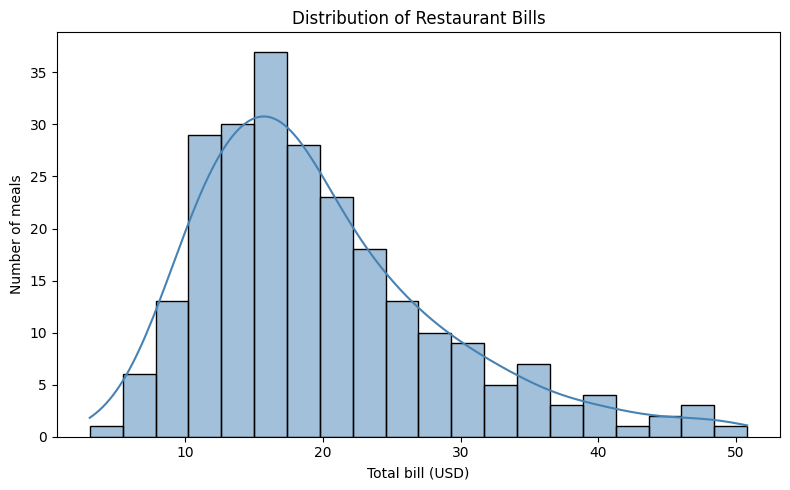

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="total_bill", bins=20, kde=True, color="steelblue")
plt.title("Distribution of Restaurant Bills")
plt.xlabel("Total bill (USD)")
plt.ylabel("Number of meals")
plt.tight_layout()
plt.show()


## 2. Bar chart — Average tip by day

**Question:** Which day has the highest average tip?

**Takeaway:** The bar chart compares the average tip amount across the days represented in the dataset.


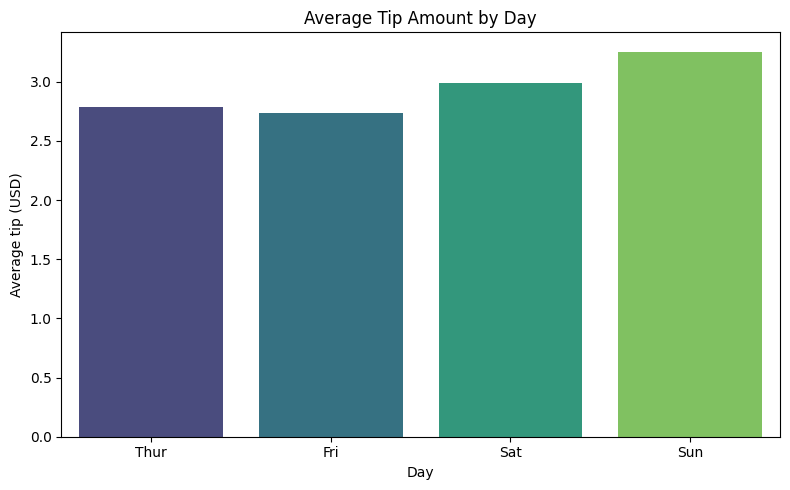

In [6]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="day", y="tip", estimator=np.mean, errorbar=None,
            hue="day", palette="viridis", legend=False)
plt.title("Average Tip Amount by Day")
plt.xlabel("Day")
plt.ylabel("Average tip (USD)")
plt.tight_layout()
plt.show()


## 3. Box plot — Tip distribution by day

**Question:** How do tips vary across different days?

**Takeaway:** The box plot compares the median, spread, and potential outliers in tip amounts across days.


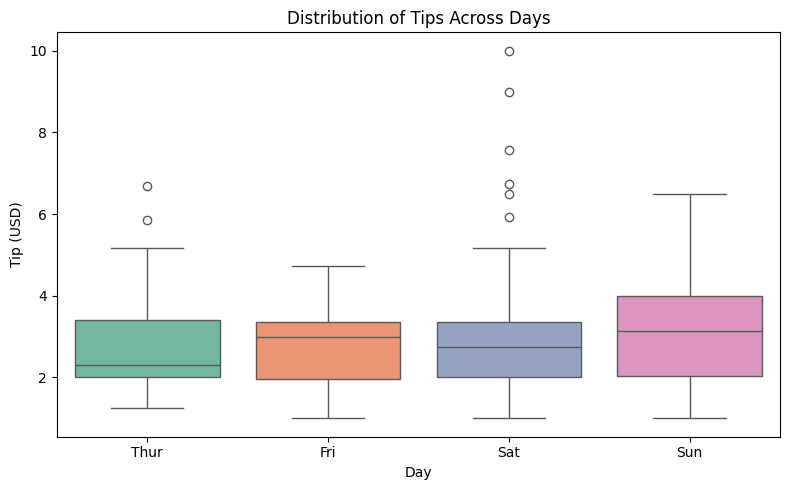

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="day", y="tip", hue="day", palette="Set2", legend=False)
plt.title("Distribution of Tips Across Days")
plt.xlabel("Day")
plt.ylabel("Tip (USD)")
plt.tight_layout()
plt.show()


## 4. Scatter plot — Total bill versus tip

**Question:** Does a higher bill tend to come with a higher tip?

**Takeaway:** The scatter plot helps assess the relationship between total bill and tip amount; it shows association, not causation.


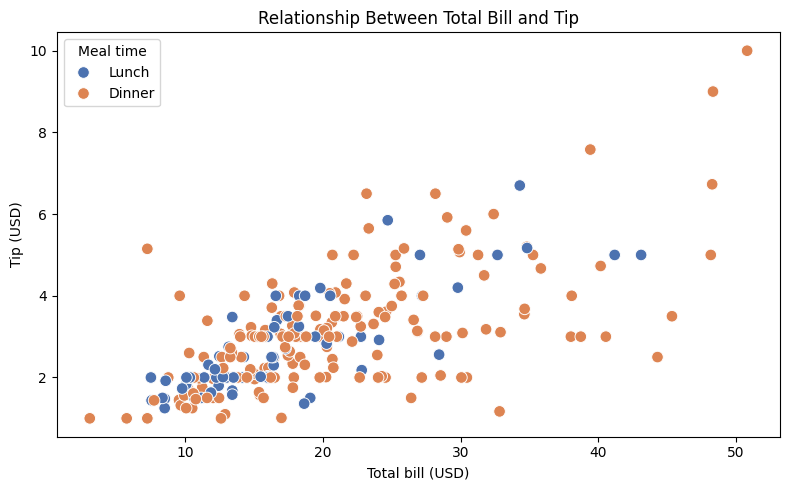

In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="total_bill", y="tip", hue="time", palette="deep", s=70)
plt.title("Relationship Between Total Bill and Tip")
plt.xlabel("Total bill (USD)")
plt.ylabel("Tip (USD)")
plt.legend(title="Meal time")
plt.tight_layout()
plt.show()


## 5. Correlation heatmap

**Question:** Which numerical variables move together?

**Takeaway:** The annotated heatmap displays pairwise correlations among numeric columns. Values closer to +1 indicate stronger positive linear association; values closer to -1 indicate stronger negative linear association.


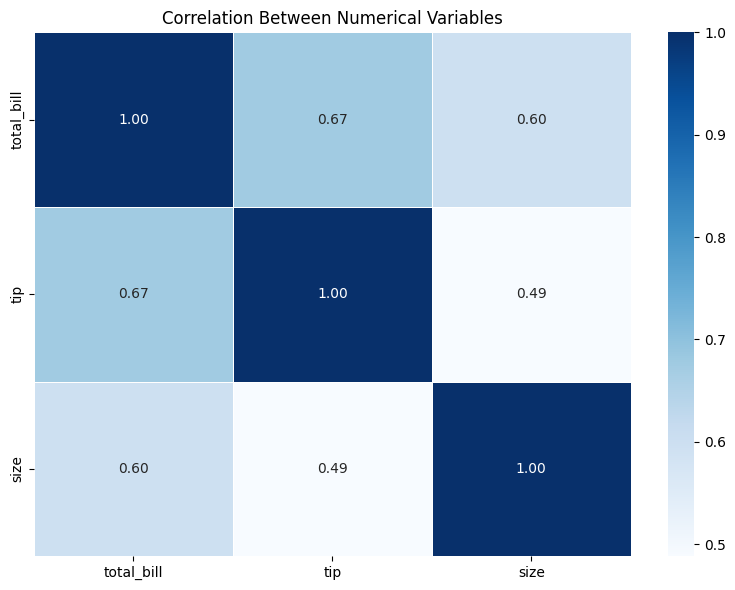

,total_bill,tip,size
total_bill,1.000000,0.674998,0.597589
tip,0.674998,1.000000,0.488400
size,0.597589,0.488400,1.000000


In [9]:
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="Blues", fmt=".2f", linewidths=0.5)
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

display(correlation)


## 6. Combined visualization dashboard

The dashboard places the five required chart types into a single image. It is saved at 150 DPI for submission.


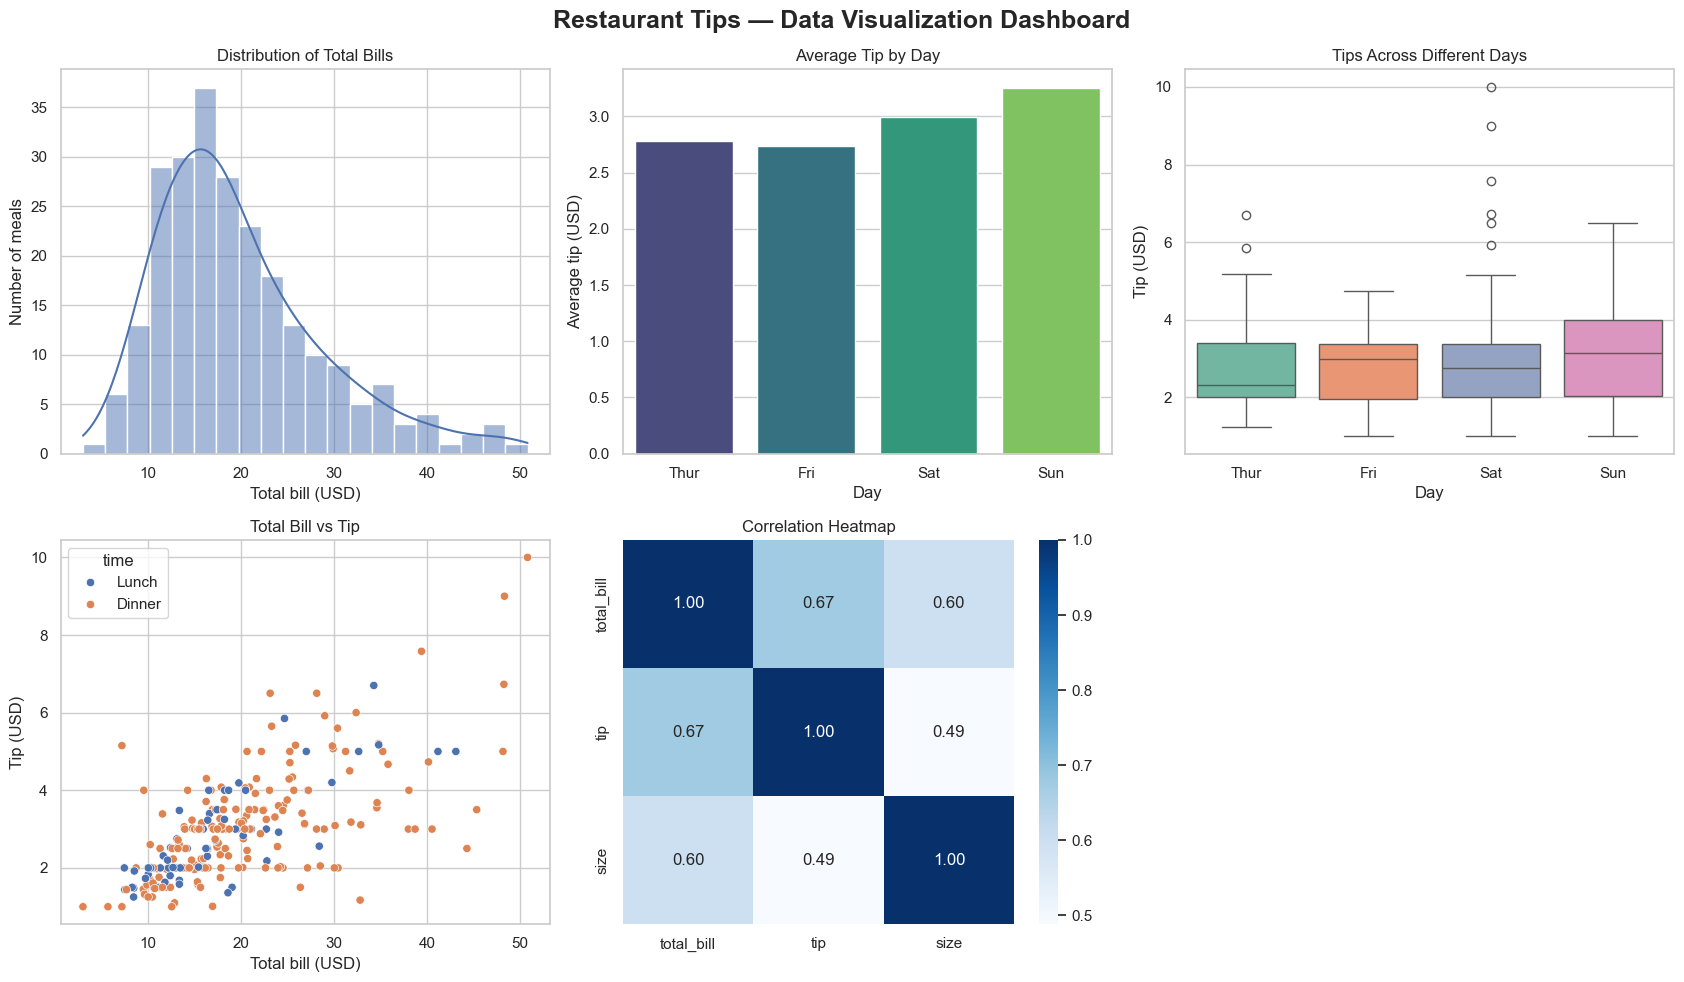

Saved: tips_dashboard.png


In [10]:
sns.set_theme(style="whitegrid", palette="deep")
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

sns.histplot(data=df, x="total_bill", bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set(title="Distribution of Total Bills", xlabel="Total bill (USD)", ylabel="Number of meals")

sns.barplot(data=df, x="day", y="tip", estimator=np.mean, errorbar=None,
            hue="day", palette="viridis", legend=False, ax=axes[0, 1])
axes[0, 1].set(title="Average Tip by Day", xlabel="Day", ylabel="Average tip (USD)")

sns.boxplot(data=df, x="day", y="tip", hue="day", palette="Set2", legend=False, ax=axes[0, 2])
axes[0, 2].set(title="Tips Across Different Days", xlabel="Day", ylabel="Tip (USD)")

sns.scatterplot(data=df, x="total_bill", y="tip", hue="time", palette="deep", ax=axes[1, 0])
axes[1, 0].set(title="Total Bill vs Tip", xlabel="Total bill (USD)", ylabel="Tip (USD)")

sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="Blues",
            fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap")

axes[1, 2].axis("off")
fig.suptitle("Restaurant Tips — Data Visualization Dashboard", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.savefig("tips_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: tips_dashboard.png")


## 7. Statistical findings

The following cell calculates the values from the dataset at runtime. Use the printed results when writing the final observations.


In [11]:
print("PROJECT FINDINGS")
print("-" * 45)
print("Number of records:", len(df))
print("Average total bill (USD):", round(df["total_bill"].mean(), 2))
print("Average tip (USD):", round(df["tip"].mean(), 2))
print("Day with highest average tip:",
      df.groupby("day", observed=True)["tip"].mean().idxmax())
print("Correlation between total bill and tip:",
      round(df["total_bill"].corr(df["tip"]), 3))
print("Most common meal time:", df["time"].mode()[0])


PROJECT FINDINGS
---------------------------------------------
Number of records: 243
Average total bill (USD): 19.81
Average tip (USD): 3.0
Day with highest average tip: Sun
Correlation between total bill and tip: 0.675
Most common meal time: Dinner


## Conclusion

This project uses Pandas, Matplotlib, and Seaborn to explore the Seaborn Tips dataset. Histograms, bar charts, box plots, scatter plots, and a correlation heatmap provide different views of the data.

The visualizations help describe restaurant bill distributions, compare tip amounts across days, examine variation in tips, and investigate the relationship between bills and tips. Correlation indicates association and should not be interpreted as proof of causation.

## Submission contents

- This Jupyter Notebook (`Project_02_Data_Visualization.ipynb`)
- The generated dashboard image (`tips_dashboard.png`)
- This README file

**Run all notebook cells before submitting.** The `sns.load_dataset("tips")` command may require an internet connection the first time the dataset is downloaded.
